<a href="https://colab.research.google.com/github/epro-tech-create/COU07506-labs/blob/main/COU07506_Week03_240242421899.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



> Add blockquote
 COU 07506 Digital Signal Processing
 Week 03 – Lab 1B
 Convolution, Correlation and Difference Equations

Name:Gasper Denis Mwansisya
Registration Number:240242421899
Class:BENG24COE


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy import signal
import time

plt.rcParams["figure.figsize"] = (9, 3.5)

In [2]:
x = [1, -1, 2]
h = [2, 1, 0, 1]

y = np.convolve(x, h)

print("Convolution result:", y)

Convolution result: [ 2 -1  3  3 -1  2]


Task 3.1 - Convulation from the definition

In [3]:
def conv(x, h):

    N = len(x) + len(h) - 1

    y = np.zeros(N)

    for n in range(N):

        for k in range(len(x)):

            if 0 <= n-k < len(h):

                y[n] += x[k] * h[n-k]

    return y

In [4]:
x = [1, 2, 3, 1]
h = [1, 1, 1]

# Manual convolution
y_manual = conv(x, h)

# NumPy convolution
y_numpy = np.convolve(x, h)

print("Manual convolution:", y_manual)
print("NumPy convolution:", y_numpy)

print("Results match:",
      np.allclose(y_manual, y_numpy))

Manual convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]
Results match: True


In [5]:
rng = np.random.default_rng(42)

# Generate two random sequences
x = rng.standard_normal(2000)
h = rng.standard_normal(2000)

# Time manual convolution
start = time.perf_counter()

y_manual = conv(x, h)

manual_time = time.perf_counter() - start

# Time NumPy convolution
start = time.perf_counter()

y_numpy = np.convolve(x, h)

numpy_time = time.perf_counter() - start

print("Manual convolution time:",
      manual_time, "seconds")

print("NumPy convolution time:",
      numpy_time, "seconds")

print("Speed improvement:",
      manual_time / numpy_time, "times")

Manual convolution time: 4.635850985000047 seconds
NumPy convolution time: 0.0027442929999779153 seconds
Speed improvement: 1689.269689875445 times


Task 3.2-  Smoothing a noisy signal by convolution

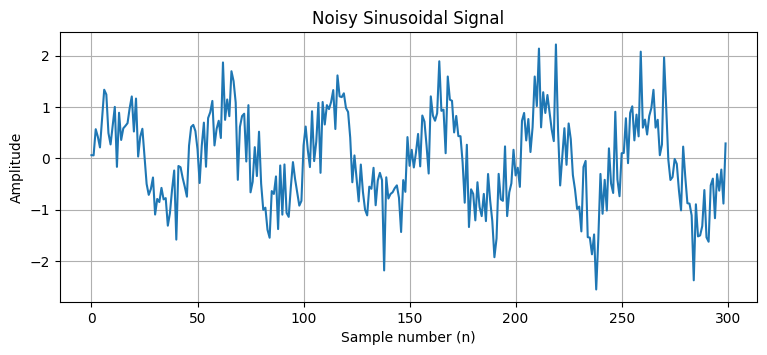

In [6]:
rng = np.random.default_rng(0)

n = np.arange(300)

# Generate Gaussian noise
w = rng.standard_normal(300)

# Generate noisy sinusoidal signal
x = np.sin(2*np.pi*n/50) + 0.5*w

plt.plot(n, x)

plt.title("Noisy Sinusoidal Signal")
plt.xlabel("Sample number (n)")
plt.ylabel("Amplitude")

plt.grid(True)
plt.show()

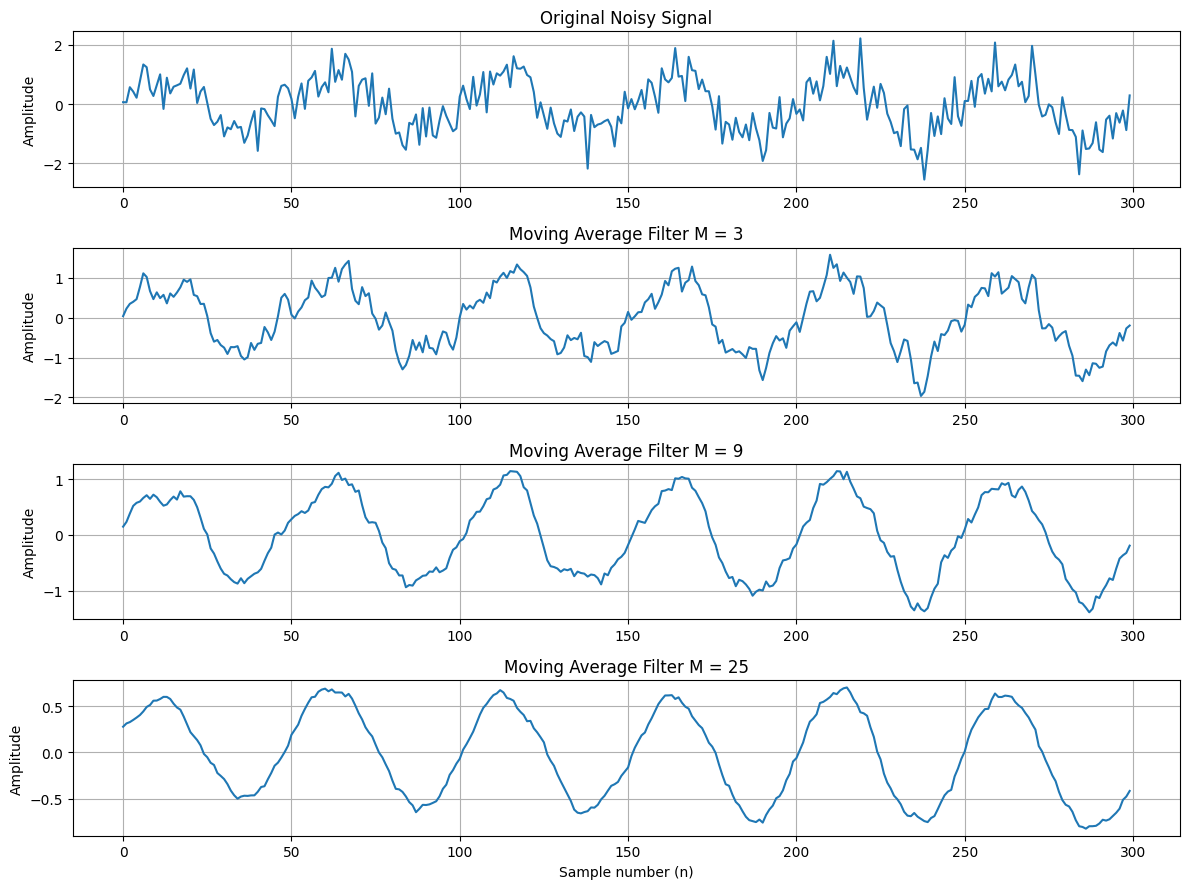

In [7]:
M_values = [3, 9, 25]

plt.figure(figsize=(12, 9))

# Original noisy signal
plt.subplot(4, 1, 1)

plt.plot(n, x)

plt.title("Original Noisy Signal")
plt.ylabel("Amplitude")
plt.grid(True)

for i, M in enumerate(M_values):

    # Create moving-average filter
    h = np.ones(M) / M

    # Apply convolution
    y = np.convolve(x, h, mode="same")

    plt.subplot(4, 1, i+2)

    plt.plot(n, y)

    plt.title(f"Moving Average Filter M = {M}")
    plt.ylabel("Amplitude")
    plt.grid(True)

plt.xlabel("Sample number (n)")
plt.tight_layout()
plt.show()

Task 3.3 — Testing linearity and time-invariance numerically

In [8]:
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

a, b = 2.0, -3.0

systems = {

    "x^2": lambda x: x**2,

    "n x(n)": lambda x:
        np.arange(len(x)) * x,

    "moving average": lambda x:
        np.convolve(x, np.ones(3)/3)[:len(x)]

}

for name, T in systems.items():

    # Test linearity
    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    # Delay input by 5 samples
    xd = np.concatenate([
        np.zeros(5), x1
    ])[:50]

    # Delay original output by 5 samples
    yd = np.concatenate([
        np.zeros(5), T(x1)
    ])[:50]

    # Test time invariance
    tinv = np.allclose(T(xd), yd)

    print(
        f"{name:15s} "
        f"linear={linear} "
        f"time-invariant={tinv}"
    )

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


Task 3.4 – Finding a hidden delay with cross-correlation

In [9]:
rng = np.random.default_rng(1)

fs = 1000

# Generate transmitted signal
x = rng.standard_normal(500)

# Actual delay
true_delay = 37

# Generate received signal
y = np.concatenate([
    np.zeros(true_delay),
    0.6*x
])[:500] + 0.5*rng.standard_normal(500)

print("Transmitted signal length:", len(x))
print("Received signal length:", len(y))
print("Actual delay:", true_delay, "samples")

Transmitted signal length: 500
Received signal length: 500
Actual delay: 37 samples


In [10]:
np.zeros(true_delay)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0.])

In [11]:
0.5*rng.standard_normal(500)

array([ 9.74197816e-02,  4.19358997e-01, -1.38246402e-02,  3.91215896e-01,
       -1.28772151e+00, -5.57838542e-01,  8.55721399e-01, -6.16759449e-01,
       -1.46652385e-01,  3.46301768e-01, -4.48359801e-01,  3.54187248e-01,
       -7.21128223e-01, -9.63753092e-01, -6.71726151e-01, -8.33933707e-01,
       -1.59296874e-02, -1.65969666e-01,  1.57138796e-01, -5.24947235e-01,
        1.26437869e+00, -5.48104142e-02, -2.99586944e-02,  2.20830068e-01,
       -1.28799877e-01, -3.22760392e-01,  3.58992717e-02,  4.52388790e-01,
        3.25879526e-01,  4.64040177e-01, -2.88890349e-01, -3.94150856e-01,
        9.95583537e-01, -1.25944883e-01,  2.32846873e-01,  3.62960919e-01,
        7.04251176e-01, -6.81614117e-01, -2.46034615e-01, -2.22646653e-01,
       -1.56540344e-01, -1.21211756e+00, -5.37980474e-02, -1.45258663e+00,
        1.43546699e-01,  2.63423858e-01,  2.93711170e-01, -6.07540832e-01,
        4.72523909e-01, -4.36953635e-01, -6.18413576e-01, -4.94914487e-01,
       -4.28519131e-01,  

In [12]:
# Calculate cross-correlation
r = signal.correlate(y, x, mode="full")

# Calculate corresponding lags
lags = signal.correlation_lags(
    len(y),
    len(x),
    mode="full"
)

# Find the maximum correlation
estimated_delay = lags[np.argmax(r)]

print("Actual delay:",
      true_delay, "samples")

print("Estimated delay:",
      estimated_delay, "samples")

Actual delay: 37 samples
Estimated delay: 37 samples


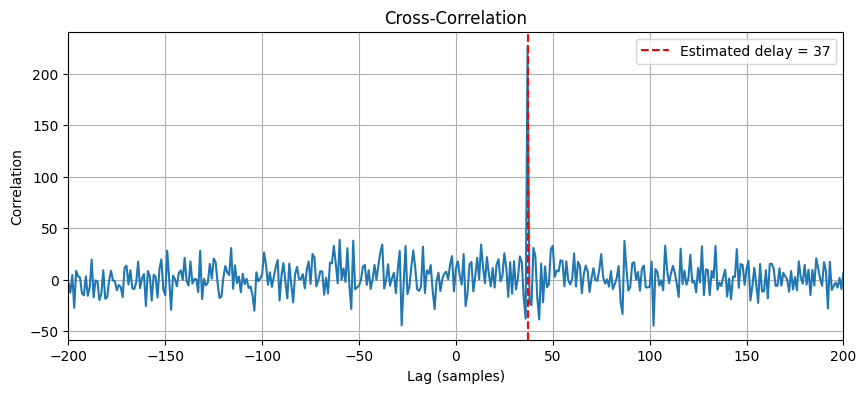

In [13]:
plt.figure(figsize=(10, 4))

plt.plot(lags, r)

plt.axvline(
    estimated_delay,
    color="red",
    linestyle="--",
    label=f"Estimated delay = {estimated_delay}"
)

plt.xlim(-200, 200)

plt.title("Cross-Correlation")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")

plt.legend()
plt.grid(True)
plt.show()

In [14]:
noise_levels = [0.5, 1, 2, 4]

for noise_std in noise_levels:

    # Generate received signal
    y = np.concatenate([
        np.zeros(true_delay),
        0.6*x
    ])[:500] + noise_std*rng.standard_normal(500)

    # Cross-correlation
    r = signal.correlate(
        y, x, mode="full"
    )

    # Find lag
    lags = signal.correlation_lags(
        len(y), len(x), mode="full"
    )

    estimated_delay = lags[np.argmax(r)]

    print(
        f"Noise = {noise_std}: "
        f"Estimated delay = {estimated_delay} samples"
    )

Noise = 0.5: Estimated delay = 37 samples
Noise = 1: Estimated delay = 37 samples
Noise = 2: Estimated delay = 37 samples
Noise = 4: Estimated delay = 37 samples


Task 3.5

In [15]:
N = 10

# Create impulse signal
impulse = np.zeros(N)

impulse[0] = 1

# Initialize impulse response
h_recursive = np.zeros(N)

# Direct recursion
for n in range(N):

    x_n = impulse[n]

    x_n1 = impulse[n-1] if n >= 1 else 0

    y_n1 = h_recursive[n-1] if n >= 1 else 0

    y_n2 = h_recursive[n-2] if n >= 2 else 0

    h_recursive[n] = (
        x_n + x_n1
        + 0.75*y_n1
        - 0.125*y_n2
    )

print("Impulse response:")
print(h_recursive)

Impulse response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [16]:
signal.lfilter(b, a, x)

array([-5.18376288e-01, -1.23242722e+00, -4.95655614e-01,  1.95473585e+00,
       -1.35803380e+00, -6.69561859e-01,  8.05429853e-01, -8.71677156e-01,
       -5.46858594e-01, -4.41198745e-01, -4.26333620e-02, -8.20069480e-01,
        1.10468113e+00,  2.44364922e-01,  7.23178969e-01, -8.98269319e-01,
       -5.95831612e-02,  4.38685126e-01,  1.17286269e+00,  3.85788361e-01,
       -1.22132708e-02,  4.13404358e-01, -1.94109572e+00, -1.51008647e+00,
        4.06674372e+00,  2.83351987e+00,  2.62158138e-01,  6.33285617e-01,
       -3.20464496e-01, -3.25982897e-01, -3.17675813e+00,  1.66803114e+00,
        5.66407511e-01, -3.06415741e+00, -9.70054494e-01, -9.94595059e-01,
        7.71009558e-01,  2.47211276e+00, -2.51197116e-01, -1.63521132e-01,
        1.84102808e+00,  1.02483999e+00,  1.08065520e-01,  1.41712743e+00,
        1.47404952e-01, -1.43224541e-01, -5.33793556e-02,  7.59437487e-01,
       -8.90622108e-01, -1.33675043e+00, -4.81272457e-01,  1.22734534e+00,
       -1.09747843e+00,  

In [17]:
b = [1, 1]

a = [1, -0.75, 0.125]

impulse = np.zeros(10)

impulse[0] = 1

h_lfilter = signal.lfilter(
    b, a, impulse
)

print("Impulse response using lfilter:")
print(h_lfilter)

Impulse response using lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [18]:
n = np.arange(10)

h_closed = (
    6*(0.5)**n
    - 5*(0.25)**n
)

print("Closed-form impulse response:")
print(h_closed)

Closed-form impulse response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [19]:
print("Direct recursion:")
print(h_recursive)

print("\nlfilter:")
print(h_lfilter)

print("\nClosed form:")
print(h_closed)

print("\nRecursion matches lfilter:",
      np.allclose(h_recursive, h_lfilter))

print("lfilter matches closed form:",
      np.allclose(h_lfilter, h_closed))

Direct recursion:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Closed form:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Recursion matches lfilter: True
lfilter matches closed form: True


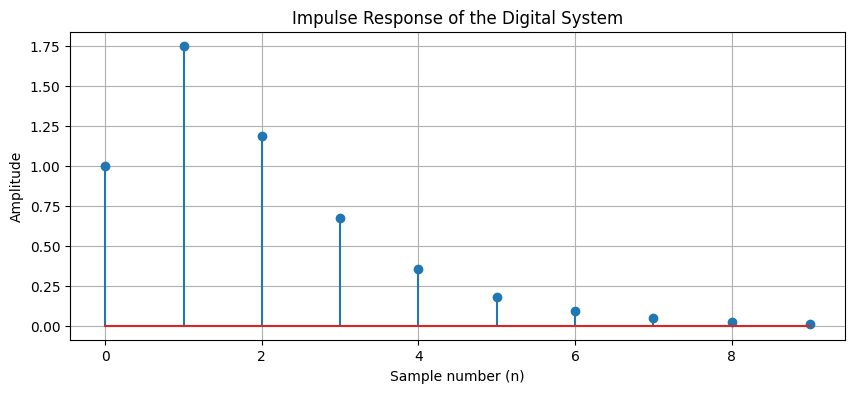

In [20]:
plt.figure(figsize=(10, 4))

plt.stem(
    n,
    h_lfilter
)

plt.title("Impulse Response of the Digital System")

plt.xlabel("Sample number (n)")
plt.ylabel("Amplitude")

plt.grid(True)
plt.show()

Final step response: 5.333333333333333


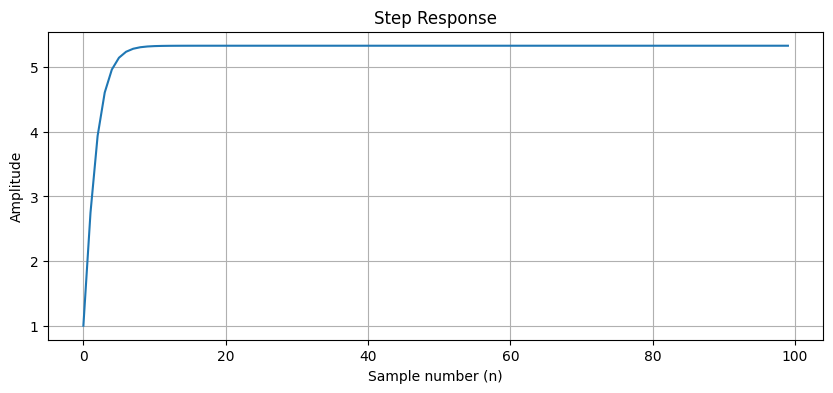

In [21]:
# Generate unit step signal
step = np.ones(100)

# Calculate step response
step_response = signal.lfilter(
    b, a, step
)

print("Final step response:",
      step_response[-1])

plt.figure(figsize=(10, 4))

plt.plot(step_response)

plt.title("Step Response")

plt.xlabel("Sample number (n)")
plt.ylabel("Amplitude")

plt.grid(True)
plt.show()

In [22]:
H1 = sum(b) / sum(a)

print("Theoretical final value:", H1)

print("Experimental final value:",
      step_response[-1])

print("Difference:",
      abs(H1 - step_response[-1]))

Theoretical final value: 5.333333333333333
Experimental final value: 5.333333333333333
Difference: 0.0


AI tools used: ChatGPT

Used for:
Understanding convolution, correlation,
difference equations and Python implementation.

How I verified the output:
Compared manual convolution with np.convolve,
checked system properties mathematically,
compared the three impulse response methods,
and verified the final step response using H(1).

All submitted code and results have been reviewed
and understood by me.